# 評価指標 — 「精度 95%」は何も言っていない

**出典**　機械学習 4 分野の教科書 — 第 4 章 1-C アンサンブルと評価 ／ 05 評価指標

**このノートのパス**　`ml-code/04_ensemble_eval/06_classification_metrics.ipynb`

**このノートで確かめること**

1. 陽性 1% のデータで「全部陰性」と答えるだけのモデルが、精度でどう見えるか
2. 閾値を動かすと適合率・再現率・誤検知数・見逃し数がどう動くか。コストから閾値を決めるとどうなるか
3. ROC-AUC と PR-AUC で、同じモデルの見え方がどれだけ違うか
4. 無関係な乱数列を特徴量に足すと、訓練データの R² がどう動くか

| 項目 | 内容 |
|---|---|
| 必要なパッケージ | `numpy`, `scikit-learn`, `matplotlib` |
| 実行時間の目安 | 約 10 秒 |
| 前提 | **このノート単体で完結する**（他のノートを先に実行する必要はない） |

In [1]:
# 未導入なら実行する（Colab など）
# !pip install -q numpy scikit-learn matplotlib

## ① 不均衡データの罠：何もしないモデルが精度 99%

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# 陽性がおよそ 1% のデータ（不正検知・故障予知のような状況）
X, y = make_classification(n_samples=20000, n_features=20, n_informative=6,
                           weights=[0.99], flip_y=0, class_sep=1.2, random_state=0)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.5, stratify=y, random_state=0)
print(f"テストデータ: {len(y_te)} 件中 陽性 {y_te.sum()} 件（{y_te.mean():.2%}）\n")

dummy = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr)   # 常に「陰性」
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_tr, y_tr)

print(f"{'モデル':<10} {'精度':>6} {'適合率':>6} {'再現率':>6} {'F1':>6} {'ROC-AUC':>8} {'PR-AUC':>7}")
for name, m in [("全部陰性", dummy), ("ロジスティック", clf)]:
    pred, score = m.predict(X_te), m.predict_proba(X_te)[:, 1]
    print(f"{name:<9} {accuracy_score(y_te, pred):>8.3f} "
          f"{precision_score(y_te, pred, zero_division=0):>8.3f} "
          f"{recall_score(y_te, pred):>8.3f} {f1_score(y_te, pred):>7.3f} "
          f"{roc_auc_score(y_te, score):>8.3f} {average_precision_score(y_te, score):>8.3f}")

tn, fp, fn, tp = confusion_matrix(y_te, clf.predict(X_te)).ravel()
print(f"\nロジスティック（閾値 0.5）の混同行列:  TP={tp}  FN={fn}  FP={fp}  TN={tn}")

テストデータ: 10000 件中 陽性 100 件（1.00%）

モデル            精度    適合率    再現率     F1  ROC-AUC  PR-AUC
全部陰性         0.990    0.000    0.000   0.000    0.500    0.010
ロジスティック      0.992    0.774    0.240   0.366    0.974    0.435

ロジスティック（閾値 0.5）の混同行列:  TP=24  FN=76  FP=7  TN=9893


## ② 閾値を動かす：適合率と再現率のトレードオフ

`predict()` は確率 0.5 で線を引いている。閾値を下げると見逃し（FN）は減るが、誤検知（FP）が増える。
ここでは **見逃し 1 件 = 100、誤検知 1 件 = 1** のコストだとして、総コスト最小の閾値を探す。

In [3]:
score = clf.predict_proba(X_te)[:, 1]
COST_FN, COST_FP = 100, 1                      # 見逃し 1 件は誤検知 100 件ぶん痛い、と業務側で決めた

print(f"{'閾値':>6} {'適合率':>6} {'再現率':>6} {'見逃しFN':>8} {'誤検知FP':>8} {'総コスト':>8}")
for th in [0.5, 0.3, 0.1, 0.05, 0.02, 0.01]:
    pred = (score >= th).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
    print(f"{th:>7.2f} {precision_score(y_te, pred, zero_division=0):>8.3f} "
          f"{recall_score(y_te, pred):>8.3f} {fn:>9} {fp:>10} {COST_FN*fn + COST_FP*fp:>10}")

ths = np.linspace(0.001, 0.9, 900)
costs = [COST_FN * ((score < t) & (y_te == 1)).sum() + COST_FP * ((score >= t) & (y_te == 0)).sum()
         for t in ths]
best = ths[int(np.argmin(costs))]
print(f"\n総コスト最小の閾値: {best:.3f}（総コスト {min(costs)}）")

    閾値    適合率    再現率    見逃しFN    誤検知FP     総コスト
   0.50    0.774    0.240        76          7       7607
   0.30    0.548    0.340        66         28       6628
   0.10    0.314    0.610        39        133       4033
   0.05    0.206    0.710        29        273       3173
   0.02    0.137    0.880        12        554       1754
   0.01    0.090    0.930         7        936       1636

総コスト最小の閾値: 0.009（総コスト 1618）


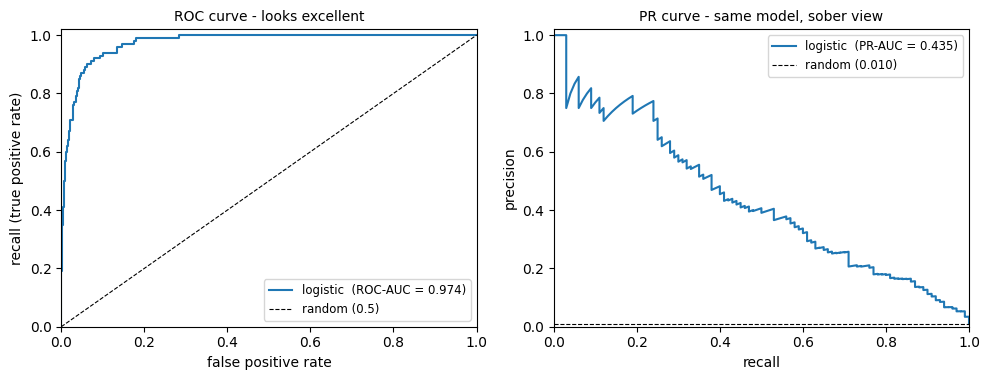

In [4]:
from sklearn.metrics import precision_recall_curve, roc_curve

fpr, tpr, _ = roc_curve(y_te, score)
prec, rec, _ = precision_recall_curve(y_te, score)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.9))
axes[0].plot(fpr, tpr, label=f"logistic  (ROC-AUC = {roc_auc_score(y_te, score):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8, label="random (0.5)")
axes[0].set_xlabel("false positive rate"); axes[0].set_ylabel("recall (true positive rate)")
axes[0].set_title("ROC curve - looks excellent", fontsize=10)
axes[1].plot(rec, prec, label=f"logistic  (PR-AUC = {average_precision_score(y_te, score):.3f})")
axes[1].axhline(y_te.mean(), color="k", ls="--", lw=0.8, label=f"random ({y_te.mean():.3f})")
axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision")
axes[1].set_title("PR curve - same model, sober view", fontsize=10)
for ax in axes:
    ax.legend(fontsize=8.5, loc="lower right" if ax is axes[0] else "upper right")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
plt.tight_layout(); plt.show()

## ③ 回帰：R² は特徴量を足すだけで上がる

真の特徴量 5 個の回帰データ（訓練 150 件）に、**目的変数と無関係な乱数列**を足していく。

In [5]:
from sklearn.datasets import make_regression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X, y = make_regression(n_samples=300, n_features=5, noise=30, random_state=0)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.5, random_state=0)
rng = np.random.default_rng(0)

print(f"{'乱数列':>6} {'訓練R²':>7} {'調整済R²':>8} {'検証R²':>7} {'検証RMSE':>9} {'検証MAE':>8}")
for k in [0, 20, 50, 100]:
    A_tr = np.c_[X_tr, rng.normal(size=(len(X_tr), k))]
    A_te = np.c_[X_te, rng.normal(size=(len(X_te), k))]
    m = LinearRegression().fit(A_tr, y_tr)
    r2_tr, p, n = r2_score(y_tr, m.predict(A_tr)), A_tr.shape[1], len(y_tr)
    adj = 1 - (1 - r2_tr) * (n - 1) / (n - p - 1)         # 自由度調整済み R²
    pred = m.predict(A_te)
    print(f"{k:>7} {r2_tr:>9.3f} {adj:>10.3f} {r2_score(y_te, pred):>9.3f} "
          f"{np.sqrt(mean_squared_error(y_te, pred)):>10.1f} {mean_absolute_error(y_te, pred):>9.1f}")

   乱数列    訓練R²    調整済R²    検証R²    検証RMSE    検証MAE
      0     0.937      0.935     0.930       30.1      23.4
     20     0.946      0.936     0.915       33.3      26.3
     50     0.960      0.936     0.897       36.6      27.9
    100     0.977      0.922     0.752       56.7      46.5


## 読み取りどころ

- **「全部陰性」は精度 99% だが、再現率 0・PR-AUC は陽性率そのもの**。精度だけを見ていると、何もしないモデルと本物のモデルの差がほとんど見えない。
- **閾値 0.5 は業務の都合と無関係な既定値にすぎない。**見逃しのコストが大きいなら閾値を下げる。コストを数字で置けば、閾値は計算で決まる。
- **ROC-AUC は陽性が少ないと楽観的に見える。**同じモデルでも PR-AUC で見ると改善の余地が大きいことが分かる。
- **訓練 R² は乱数列を足すだけで 1 に近づく**が、検証 R² と RMSE / MAE は悪化する。自由度調整済み R² は、この「水増し」を割り引く。比較は検証データの指標で行う。